# Indian Sign Language (ISL) Alphabet Recognition using a CNN
**Project:** PRAICP-1000-IndiSignLang (DataMites Project Mentoring PR-0019)

**Business case:** Build a Machine Learning model that recognises Indian Sign Language hand signs from images, to improve communication accessibility for the deaf and hard-of-hearing community in India.

**Project goals (from the problem statement)**
1. Image preprocessing
2. ML model to predict the sign

**Approach in one paragraph:** Audit the dataset, preprocess every image into a clean fixed-size square tensor, split the data in a *leakage-safe* way (the images are consecutive video frames, so a naive random split would inflate accuracy), train a Convolutional Neural Network (CNN) with data augmentation, and evaluate it honestly against a classical baseline, with per-class metrics, a confusion matrix, error analysis and a robustness check.

**Notebook outline**
1. Setup  2. Dataset audit  3. Preprocessing  4. Leakage check and split  5. Baseline model  6. CNN model  7. Evaluation  8. Error analysis and robustness  9. Inference demo  10. Grouped cross-validation  11. Conclusions and limitations

## 1. Setup
Import libraries, fix random seeds for reproducibility and define configuration in one place.

In [1]:
import os, re, glob, random, zipfile, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

# ---------------- Configuration ----------------
SEED       = 42          # one seed everywhere so results can be reproduced
IMG_SIZE   = 64          # every image is resized to IMG_SIZE x IMG_SIZE
BATCH_SIZE = 32
EPOCHS     = 25          # upper limit; EarlyStopping usually stops earlier
CHUNK      = 30          # number of consecutive frames treated as one "chunk" when splitting
BUFFER     = 5           # frames dropped at the edges of val/test chunks to avoid near-duplicates
ZIP_PATH   = "PRAICP-1000-IndiSignLang.zip"   # change if your zip lives elsewhere
DATA_DIR   = "Data"                            # folder that contains one sub-folder per sign

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_style("whitegrid")
print("TensorFlow:", tf.__version__, "| NumPy:", np.__version__)

I0000 00:00:1793718075.676125      95 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793718076.197675      95 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793718078.367135      95 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | NumPy: 2.4.4


## 2. Dataset audit
The data is organised as one folder per sign (the folder name is the label). Before modelling, we check the number of images per class and the image properties, because problems found here change how we should preprocess and split the data.

In [2]:
# If the dataset has not been extracted yet, extract it from the zip file.
if not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(".")
    print("Extracted dataset.")

classes = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
class_to_idx = {c: i for i, c in enumerate(classes)}
NUM_CLASSES = len(classes)

# Build a table with one row per image (reading only the header, so this is fast).
rows = []
for c in classes:
    for f in sorted(glob.glob(os.path.join(DATA_DIR, c, "*.jpg"))):
        with Image.open(f) as im:
            w, h = im.size
        rows.append(dict(path=f, label=c, y=class_to_idx[c], frame=int(re.findall(r"\d+", os.path.basename(f))[0]), w=w, h=h))
df = pd.DataFrame(rows)
df["capture"] = df.apply(lambda r: f"{r.w}x{r.h}", axis=1)

print(f"Total images : {len(df)}")
print(f"Classes      : {NUM_CLASSES} -> {classes}")
print("Note: the letters J and Z are absent from this dataset (they are not in the provided folders).")

Total images : 4972
Classes      : 24 -> ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
Note: the letters J and Z are absent from this dataset (they are not in the provided folders).


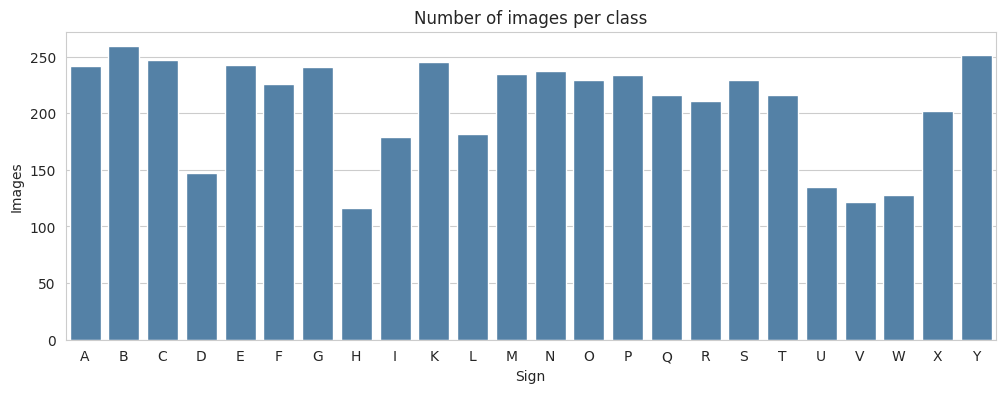

Smallest class: H (116), largest class: B (259).
Imbalance ratio (max/min) = 2.23  -> moderate, handled with class weights later.


In [3]:
# Class distribution
counts = df.label.value_counts().reindex(classes)
plt.figure(figsize=(12, 4))
sns.barplot(x=counts.index, y=counts.values, color="steelblue")
plt.title("Number of images per class"); plt.xlabel("Sign"); plt.ylabel("Images")
plt.show()
print(f"Smallest class: {counts.idxmin()} ({counts.min()}), largest class: {counts.idxmax()} ({counts.max()}).")
print(f"Imbalance ratio (max/min) = {counts.max()/counts.min():.2f}  -> moderate, handled with class weights later.")

In [4]:
# Image resolution / orientation per class
cap = pd.crosstab(df.label, df.capture)
display(cap)
print("Classes that were NOT captured at 640x480:", sorted(df[df.capture != "640x480"].label.unique()))

capture,1088x1920,1920x1088,640x480
label,,,
A,0,0,242
B,0,0,259
C,0,0,247
D,0,147,0
E,0,0,243
F,0,0,226
G,0,0,241
H,0,116,0
I,179,0,0


Classes that were NOT captured at 640x480: ['D', 'H', 'I', 'L', 'U', 'V', 'W']


**Finding 1 - capture-setup shortcut risk.** Most classes are 640x480, but seven classes (D, H, L, U, V, W at 1920x1088 and I in portrait 1088x1920) were captured with a different camera setup. If we simply stretched every image to a square, the *aspect ratio and distortion* would give away the class and a CNN could "cheat" instead of learning hand shapes. To remove this shortcut, preprocessing will **centre-crop every image to a square first** (no stretching), and later we report accuracy separately for each capture type.

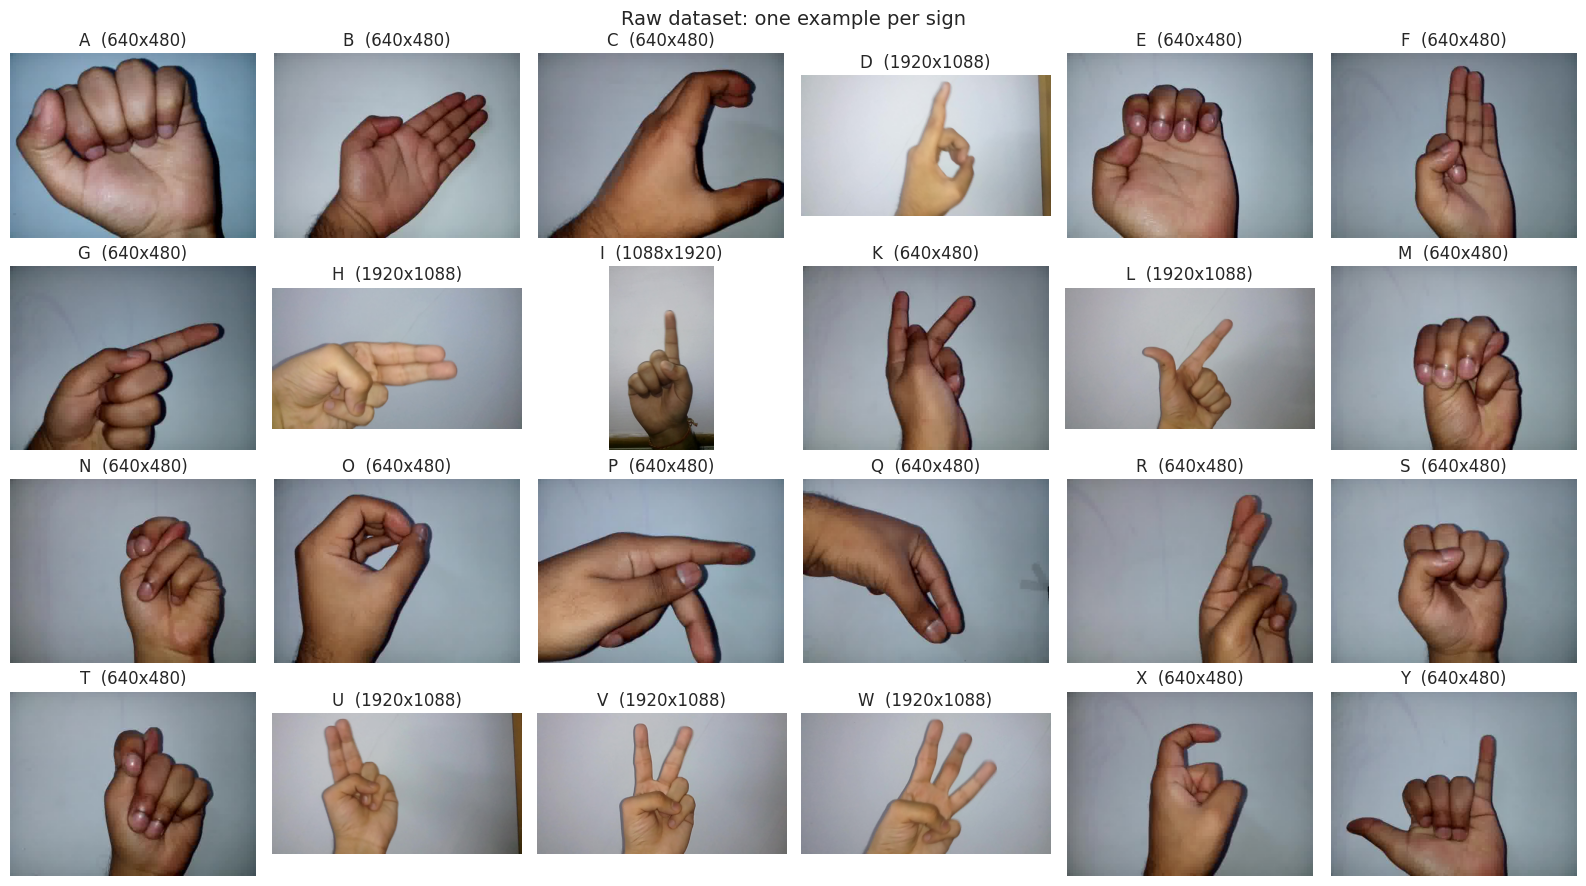

In [5]:
# One raw example per class
fig, axes = plt.subplots(4, 6, figsize=(16, 9))
for ax, c in zip(axes.ravel(), classes):
    p = df[df.label == c].iloc[len(df[df.label == c]) // 2].path
    ax.imshow(Image.open(p)); ax.set_title(f"{c}  ({Image.open(p).size[0]}x{Image.open(p).size[1]})"); ax.axis("off")
plt.suptitle("Raw dataset: one example per sign", fontsize=14); plt.tight_layout(); plt.show()

## 3. Image preprocessing (Project goal 1)
Steps applied to **every** image:
1. **Load as RGB** (colour carries useful skin/hand-edge information, so we keep 3 channels).
2. **Centre-crop to a square** using the shorter side, so the hand is not distorted and capture-setup aspect ratios cannot leak the label.
3. **Resize** to 64x64 using area interpolation (good quality when shrinking).
4. **Store as uint8**; scaling pixel values to [0, 1] happens *inside* the model (a `Rescaling` layer), so training and inference use exactly the same normalisation.

Data augmentation (rotation, zoom, shift, brightness/contrast) is applied later, **only on training data**.

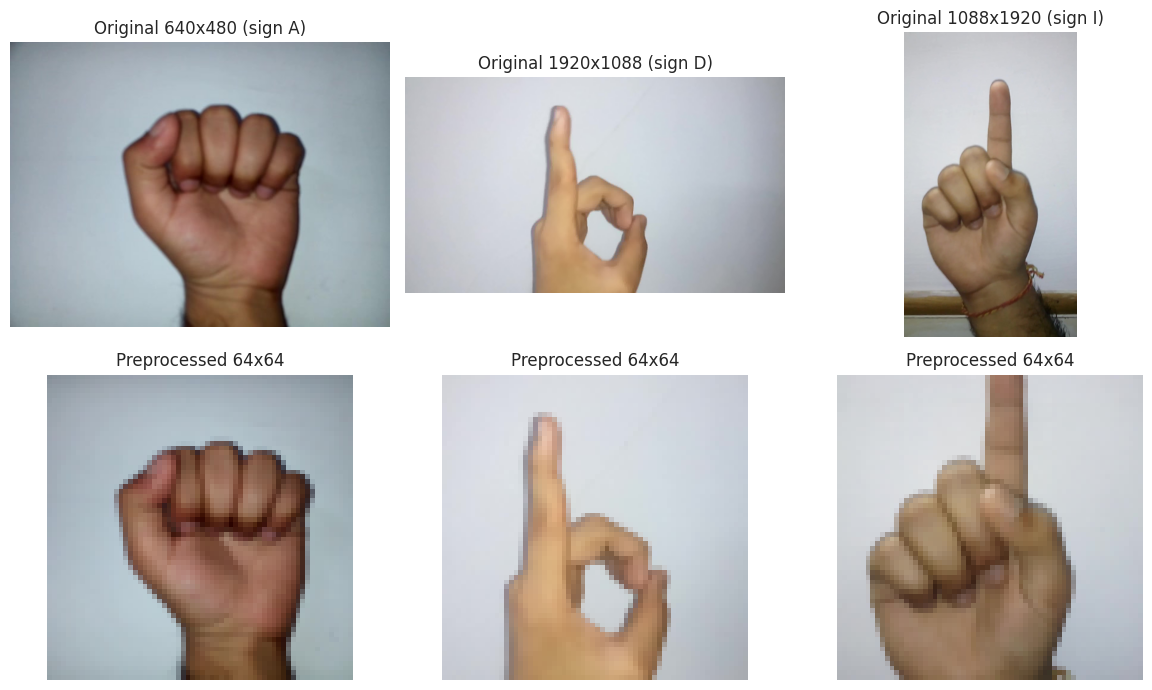

In [6]:
def preprocess(path, size=IMG_SIZE):
    """Load an image file and return a (size, size, 3) uint8 RGB array."""
    im = Image.open(path)
    im.draft("RGB", (size * 4, size * 4))     # lets JPEG decode a smaller version -> much faster for 1920x1088 files
    im = im.convert("RGB")
    w, h = im.size
    s = min(w, h)                              # side of the square crop
    left, top = (w - s) // 2, (h - s) // 2
    im = im.crop((left, top, left + s, top + s))
    im = im.resize((size, size), Image.Resampling.BOX)   # BOX = area averaging
    return np.asarray(im, dtype=np.uint8)

# Visual check on one image from each capture type (4:3, 16:9, portrait)
demo = [df[df.capture == k].iloc[10] for k in ["640x480", "1920x1088", "1088x1920"]]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for j, r in enumerate(demo):
    axes[0, j].imshow(Image.open(r.path)); axes[0, j].set_title(f"Original {r.capture} (sign {r.label})"); axes[0, j].axis("off")
    axes[1, j].imshow(preprocess(r.path)); axes[1, j].set_title(f"Preprocessed {IMG_SIZE}x{IMG_SIZE}"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

In [7]:
# Preprocess the whole dataset once and cache it (so re-running the notebook is quick).
CACHE = "isl_cache.npz"
if os.path.exists(CACHE) and np.load(CACHE)["X"].shape[1] == IMG_SIZE:
    X = np.load(CACHE)["X"]
else:
    t0 = time.time()
    X = np.stack([preprocess(p) for p in df.path])
    np.savez_compressed(CACHE, X=X)
    print(f"Preprocessed in {time.time()-t0:.0f}s")
y = df.y.values
print("X shape:", X.shape, X.dtype, "| y shape:", y.shape)
print("Pixel range:", X.min(), "-", X.max(), "| memory: %.0f MB" % (X.nbytes/1e6))

X shape: (4972, 64, 64, 3) uint8 | y shape: (4972,)
Pixel range: 0 - 255 | memory: 61 MB


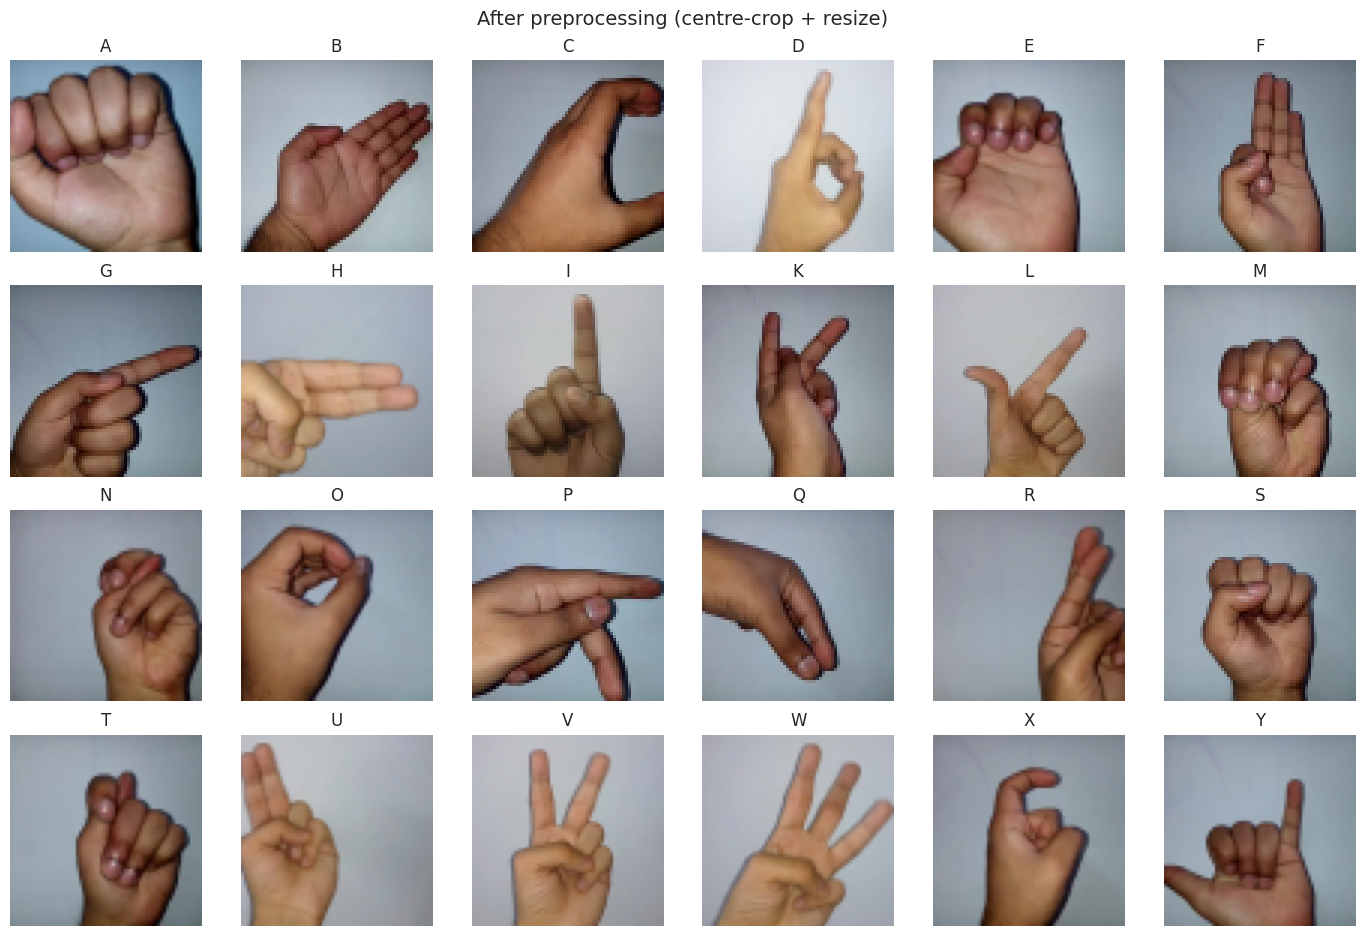

In [8]:
# Preprocessed examples: one per class
fig, axes = plt.subplots(4, 6, figsize=(14, 9.5))
for ax, c in zip(axes.ravel(), classes):
    idx = np.where(y == class_to_idx[c])[0][len(np.where(y == class_to_idx[c])[0]) // 2]
    ax.imshow(X[idx]); ax.set_title(c); ax.axis("off")
plt.suptitle("After preprocessing (centre-crop + resize)", fontsize=14); plt.tight_layout(); plt.show()

## 4. Leakage check and train / validation / test split
**Hypothesis:** file `001.jpg`, `002.jpg`, ... are consecutive frames of a short video, so neighbouring images are almost identical. If true, a normal random split puts near-copies of test images into the training set and the score becomes meaningless. We test this with pixel differences.

Mean difference, NEXT frame in same class : 7.01
Mean difference, RANDOM pair in same class: 27.98


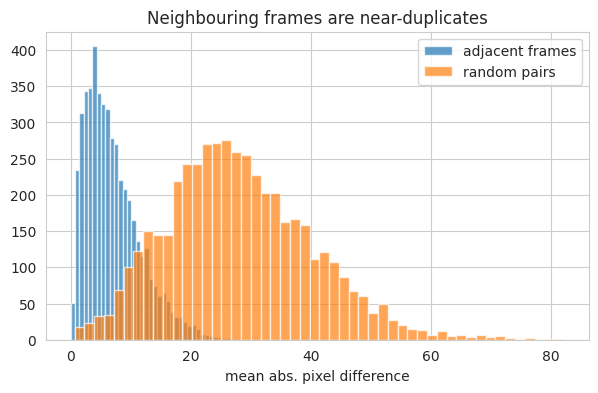

In [9]:
# Mean absolute pixel difference on small grayscale versions
G = np.stack([cv2.resize(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY), (32, 32)) for a in X]).astype(np.float32)
rng = np.random.default_rng(SEED)
adj, rnd = [], []
for c in range(NUM_CLASSES):
    idx = np.where(y == c)[0]                      # already sorted by frame number
    adj += [np.abs(G[idx[i]] - G[idx[i+1]]).mean() for i in range(len(idx)-1)]
    a, b = rng.choice(idx, 200), rng.choice(idx, 200)
    rnd += [np.abs(G[i] - G[j]).mean() for i, j in zip(a, b) if i != j]
print(f"Mean difference, NEXT frame in same class : {np.mean(adj):.2f}")
print(f"Mean difference, RANDOM pair in same class: {np.mean(rnd):.2f}")
plt.figure(figsize=(7, 4)); plt.hist(adj, bins=50, alpha=.7, label="adjacent frames"); plt.hist(rnd, bins=50, alpha=.7, label="random pairs")
plt.legend(); plt.xlabel("mean abs. pixel difference"); plt.title("Neighbouring frames are near-duplicates"); plt.show()

**Finding 2 - near-duplicate frames.** Adjacent frames differ far less than random pairs of the same sign, which confirms the images come from videos. A random split would leak. We therefore use a **chunk-based split**: each class's frames are cut into chunks of 30 consecutive frames, whole chunks are assigned to train (70%), validation (15%) or test (15%), and 5 frames at the edges of validation/test chunks are dropped so no test frame has a near-identical training neighbour.

In [10]:
def chunk_split(df, chunk=CHUNK, buffer=BUFFER, val_frac=.15, test_frac=.15, seed=SEED):
    rng = np.random.default_rng(seed)
    split = np.full(len(df), "drop", dtype=object)
    for c in range(NUM_CLASSES):
        idx = np.where(df.y.values == c)[0]
        idx = idx[np.argsort(df.frame.values[idx])]
        n_chunks = max(1, len(idx) // chunk)        # a short final remainder is merged into the last chunk
        order = rng.permutation(n_chunks)
        n_val  = max(1, round(n_chunks * val_frac))
        n_test = max(1, round(n_chunks * test_frac))
        role = {}
        for k, ch in enumerate(order):
            role[ch] = "test" if k < n_test else ("val" if k < n_test + n_val else "train")
        for ch in range(n_chunks):
            end = len(idx) if ch == n_chunks - 1 else (ch + 1) * chunk
            members = idx[ch*chunk:end]
            if role[ch] == "train":
                split[members] = "train"
            else:                                   # drop frames at both edges of val/test chunks
                keep = members[buffer:len(members)-buffer]
                split[keep] = role[ch]
    return split

df["split"] = chunk_split(df)
print(df.split.value_counts())
print()
display(pd.crosstab(df.label, df.split).T)

tr, va, te = [np.where(df.split == s)[0] for s in ["train", "val", "test"]]
X_tr, y_tr, X_va, y_va, X_te, y_te = X[tr], y[tr], X[va], y[va], X[te], y[te]
assert len(set(tr) & set(va)) == len(set(tr) & set(te)) == len(set(va) & set(te)) == 0, "splits overlap!"
for s_ in ["train", "val", "test"]:
    assert set(df.y[df.split == s_]) == set(range(NUM_CLASSES)), f"a class is missing from {s_}"   # every sign must be in every split
print("\nEvery sign appears in train, validation and test. No image appears in more than one split.  Train/Val/Test sizes:", len(tr), len(va), len(te))

split
train    3406
val       582
test      504
drop      480
Name: count, dtype: int64



label,A,B,C,D,E,F,G,H,I,K,...,P,Q,R,S,T,U,V,W,X,Y
split,,,,,,,,,,,,,,,,,,,,,
drop,20,20,20,20,20,20,20,20,20,20,...,20,20,20,20,20,20,20,20,20,20
test,20,20,20,20,20,20,20,20,20,20,...,44,20,20,20,20,20,20,20,20,20
train,182,199,180,60,183,166,181,30,119,185,...,150,156,151,169,156,60,62,68,142,191
val,20,20,27,47,20,20,20,46,20,20,...,20,20,20,20,20,35,20,20,20,20



Every sign appears in train, validation and test. No image appears in more than one split.  Train/Val/Test sizes: 3406 582 504


## 5. Baseline model: Random Forest on raw pixels
A model is only meaningful relative to a baseline. We train a simple Random Forest on 32x32 grayscale pixels. It also lets us **measure the leakage damage**: the same baseline is evaluated once with a naive random split and once with our chunk split.

In [11]:
def small_gray(arr): return np.stack([cv2.resize(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY), (32, 32)) for a in arr]).reshape(len(arr), -1) / 255.0
F = small_gray(X)

# (a) naive random split (leaky)
a_tr, a_te, b_tr, b_te = train_test_split(F, y, test_size=.15, random_state=SEED, stratify=y)
rf_leaky = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED).fit(a_tr, b_tr)
acc_leaky = accuracy_score(b_te, rf_leaky.predict(a_te))

# (b) our leakage-safe chunk split
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED).fit(F[tr], y_tr)
pred_rf = rf.predict(F[te])
acc_rf = accuracy_score(y_te, pred_rf)

print(f"Random Forest, naive random split : {acc_leaky:.3f}   <- inflated by near-duplicate frames")
print(f"Random Forest, chunk split (honest): {acc_rf:.3f}")

Random Forest, naive random split : 0.991   <- inflated by near-duplicate frames
Random Forest, chunk split (honest): 0.738


## 6. CNN model (Project goal 2)
**Architecture:** four convolution blocks (Conv - BatchNorm - ReLU - MaxPool) with increasing filters (32, 64, 128, 256), then global average pooling, dropout and a softmax layer with one output per sign. A small custom CNN is appropriate here because the images are simple (plain background, one hand) and the dataset is small, so a huge network would overfit. We use no pre-trained weights, so the notebook runs offline.

**Augmentation (training only):** small rotation, zoom, shift, brightness and contrast changes, to imitate different camera positions and lighting. We deliberately do **not** flip images horizontally, because a mirrored hand is a different hand and could change the meaning of a sign.

In [12]:
def build_cnn():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1/255.)(inp)                       # normalise pixels to [0, 1]
    # --- augmentation: active only during training ---
    x = layers.RandomRotation(0.06)(x)                      # factor 0.06 = up to +/- 6% of a full turn (about 21 degrees)
    x = layers.RandomZoom(0.12)(x)
    x = layers.RandomTranslation(0.08, 0.08)(x)
    x = layers.RandomBrightness(0.2, value_range=(0, 1))(x)
    x = layers.RandomContrast(0.2)(x)
    # --- feature extractor ---
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)                              # regularisation against overfitting
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="ISL_CNN")

model = build_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "ISL_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 64, 64, 3)      │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 64, 64, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 396,024 (1.51 MB)

 Trainable params: 395,064 (1.51 MB)

 Non-trainable params: 960 (3.75 KB)

In [13]:
# Class weights give small classes proportionally more influence during training.
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_tr)
class_weight = dict(enumerate(cw))

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("isl_best.weights.h5", monitor="val_loss", save_best_only=True, save_weights_only=True),  # safety copy of the best weights   # stop when validation stops improving
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5), # lower learning rate on plateau
]
t0 = time.time()
history = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS, batch_size=BATCH_SIZE,
                    class_weight=class_weight, callbacks=callbacks, verbose=2)
print(f"\nTraining time: {(time.time()-t0)/60:.1f} min | epochs run: {len(history.history['loss'])}")

Epoch 1/25


107/107 - 27s - 255ms/step - accuracy: 0.3720 - loss: 2.0332 - val_accuracy: 0.0344 - val_loss: 4.7406 - learning_rate: 0.0010


Epoch 2/25


107/107 - 41s - 379ms/step - accuracy: 0.7073 - loss: 0.9555 - val_accuracy: 0.0344 - val_loss: 8.0569 - learning_rate: 0.0010


Epoch 3/25


107/107 - 40s - 378ms/step - accuracy: 0.8391 - loss: 0.5780 - val_accuracy: 0.0344 - val_loss: 7.0259 - learning_rate: 0.0010


... (27 outputs left out)

107/107 - 41s - 381ms/step - accuracy: 0.9991 - loss: 0.0150 - val_accuracy: 0.8866 - val_loss: 0.4565 - learning_rate: 2.5000e-04


Epoch 18/25


107/107 - 42s - 397ms/step - accuracy: 0.9977 - loss: 0.0163 - val_accuracy: 0.8522 - val_loss: 0.6769 - learning_rate: 2.5000e-04



Training time: 12.1 min | epochs run: 18


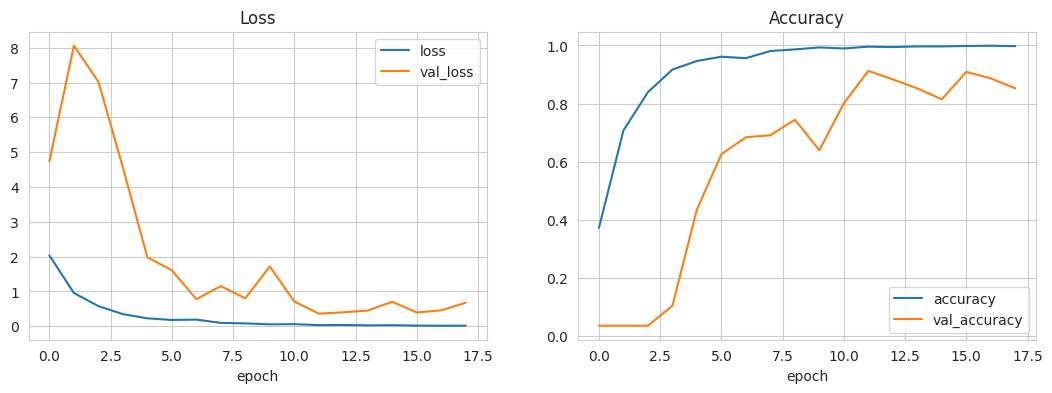

In [14]:
# Learning curves
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
h[["loss", "val_loss"]].plot(ax=ax[0]); ax[0].set_title("Loss"); ax[0].set_xlabel("epoch")
h[["accuracy", "val_accuracy"]].plot(ax=ax[1]); ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch")
plt.show()

## 7. Evaluation on the held-out test set
The test set was never used for training, tuning or early stopping, so these numbers estimate performance on unseen frames.

In [15]:
proba = model.predict(X_te, verbose=0)
pred = proba.argmax(1)
acc_cnn = accuracy_score(y_te, pred)
f1_cnn  = f1_score(y_te, pred, average="macro")
print(f"CNN test accuracy : {acc_cnn:.3f}")
print(f"CNN macro F1      : {f1_cnn:.3f}")
print(f"Top-3 accuracy    : {np.mean([y_te[i] in np.argsort(proba[i])[-3:] for i in range(len(y_te))]):.3f}\n")
print(classification_report(y_te, pred, target_names=classes, digits=3))

CNN test accuracy : 0.972
CNN macro F1      : 0.973
Top-3 accuracy    : 0.998

              precision    recall  f1-score   support

           A      0.800     1.000     0.889        20
           B      1.000     1.000     1.000        20
           C      0.833     1.000     0.909        20
           D      0.952     1.000     0.976        20
           E      1.000     1.000     1.000        20
           F      0.952     1.000     0.976        20
           G      1.000     1.000     1.000        20
           H      1.000     1.000     1.000        20
           I      1.000     1.000     1.000        20
           K      1.000     1.000     1.000        20
           L      1.000     0.950     0.974        20
           M      0.909     1.000     0.952        20
           N      1.000     0.900     0.947        20
           O      1.000     1.000     1.000        20
           P      1.000     0.909     0.952        44
           Q      1.000     1.000     1.000        20
  

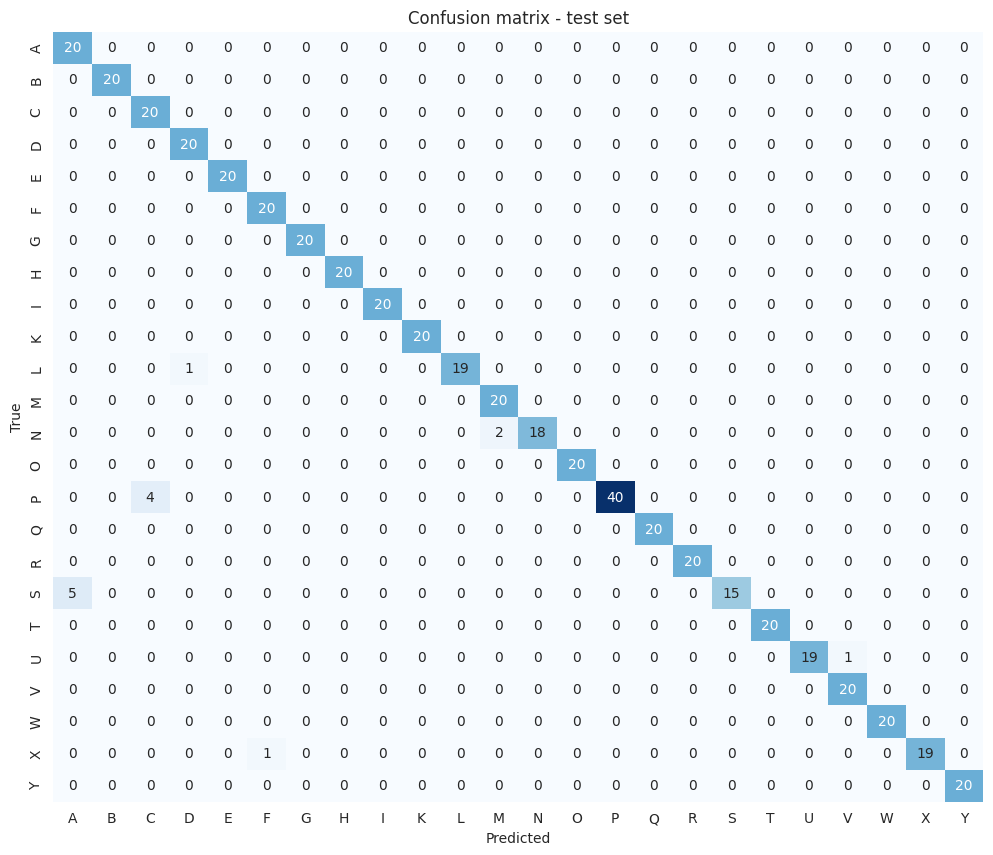

In [16]:
# Confusion matrix (rows = true sign, columns = predicted sign)
cm = confusion_matrix(y_te, pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix - test set"); plt.show()

In [17]:
# Model comparison
comp = pd.DataFrame({
    "Model": ["Random Forest (pixels, naive random split)", "Random Forest (pixels, chunk split)", "CNN (chunk split)"],
    "Accuracy": [acc_leaky, acc_rf, acc_cnn],
    "Macro F1": [np.nan, f1_score(y_te, pred_rf, average="macro"), f1_cnn],
})
display(comp.round(3))

,Model,Accuracy,Macro F1
0,"Random Forest (pixels, naive random split)",0.991,NaN
1,"Random Forest (pixels, chunk split)",0.738,0.719
2,CNN (chunk split),0.972,0.973


## 8. Error analysis and robustness
A single accuracy number hides where the model fails. We look at the weakest classes, the most frequent confusions and the actual misclassified images, then test whether performance depends on the capture setup.

In [18]:
# Weakest classes and most frequent confusions
rep = pd.DataFrame(classification_report(y_te, pred, target_names=classes, output_dict=True)).T.iloc[:NUM_CLASSES]
print("Lowest F1 classes:"); display(rep.sort_values("f1-score").head(5).round(3))

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = sorted([(cm_off[i, j], classes[i], classes[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if cm_off[i, j] > 0], reverse=True)[:8]
print("Most frequent confusions (true -> predicted):")
for n, a, b in pairs: print(f"  {a} -> {b}: {n} images")

Lowest F1 classes:


,precision,recall,f1-score,support
S,1.000,0.750,0.857,20.0
A,0.800,1.000,0.889,20.0
C,0.833,1.000,0.909,20.0
N,1.000,0.900,0.947,20.0
P,1.000,0.909,0.952,44.0


Most frequent confusions (true -> predicted):
  S -> A: 5 images
  P -> C: 4 images
  N -> M: 2 images
  X -> F: 1 images
  U -> V: 1 images
  L -> D: 1 images


14 of 504 test images misclassified


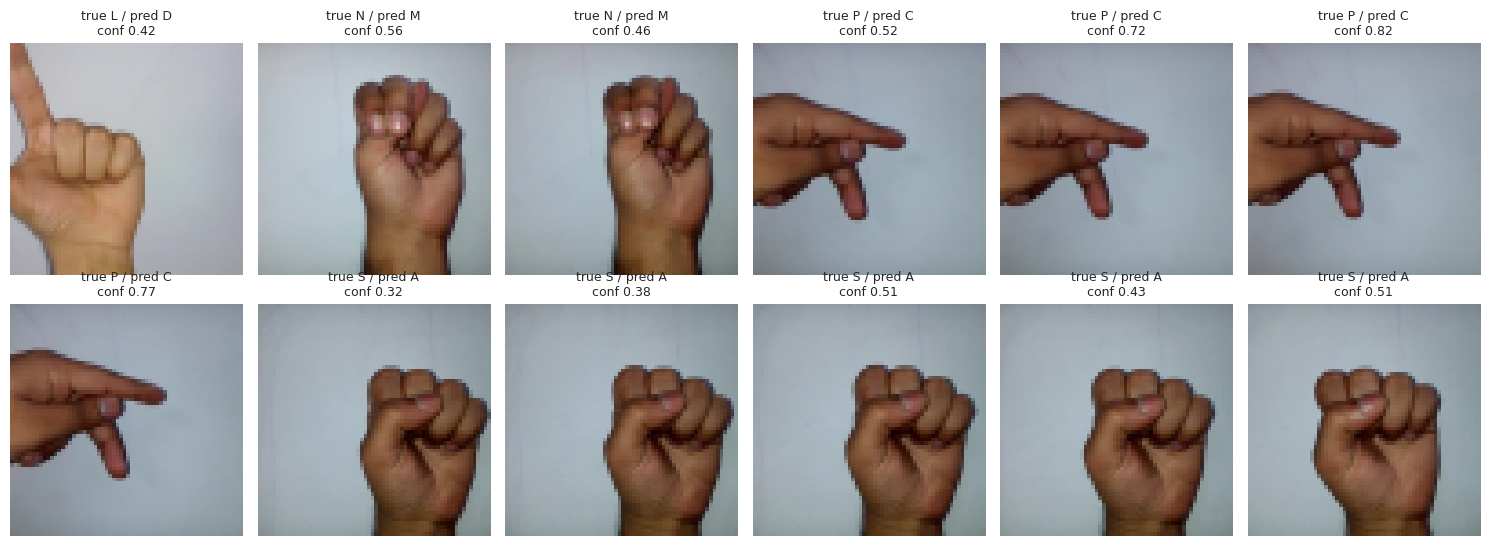

In [19]:
# Misclassified test images
wrong = np.where(pred != y_te)[0]
print(f"{len(wrong)} of {len(y_te)} test images misclassified")
show = wrong[:12]
if len(show):
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), show):
        ax.imshow(X_te[i]); ax.set_title(f"true {classes[y_te[i]]} / pred {classes[pred[i]]}\nconf {proba[i].max():.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

In [20]:
# Robustness: accuracy for each capture setup
cap_te = df.capture.values[te]
res = []
for k in sorted(set(cap_te)):
    m = cap_te == k
    res.append(dict(capture=k, classes=",".join(sorted({classes[v] for v in y_te[m]})), test_images=int(m.sum()), accuracy=accuracy_score(y_te[m], pred[m])))
display(pd.DataFrame(res).round(3))

,capture,classes,test_images,accuracy
0,1088x1920,I,20,1.000
1,1920x1088,"D,H,L,U,V,W",120,0.983
2,640x480,"A,B,C,E,F,G,K,M,N,O,P,Q,R,S,T,X,Y",364,0.967


## 9. Inference demo
A reusable function that takes any image file path and returns the predicted sign with confidence, using exactly the same preprocessing as training.

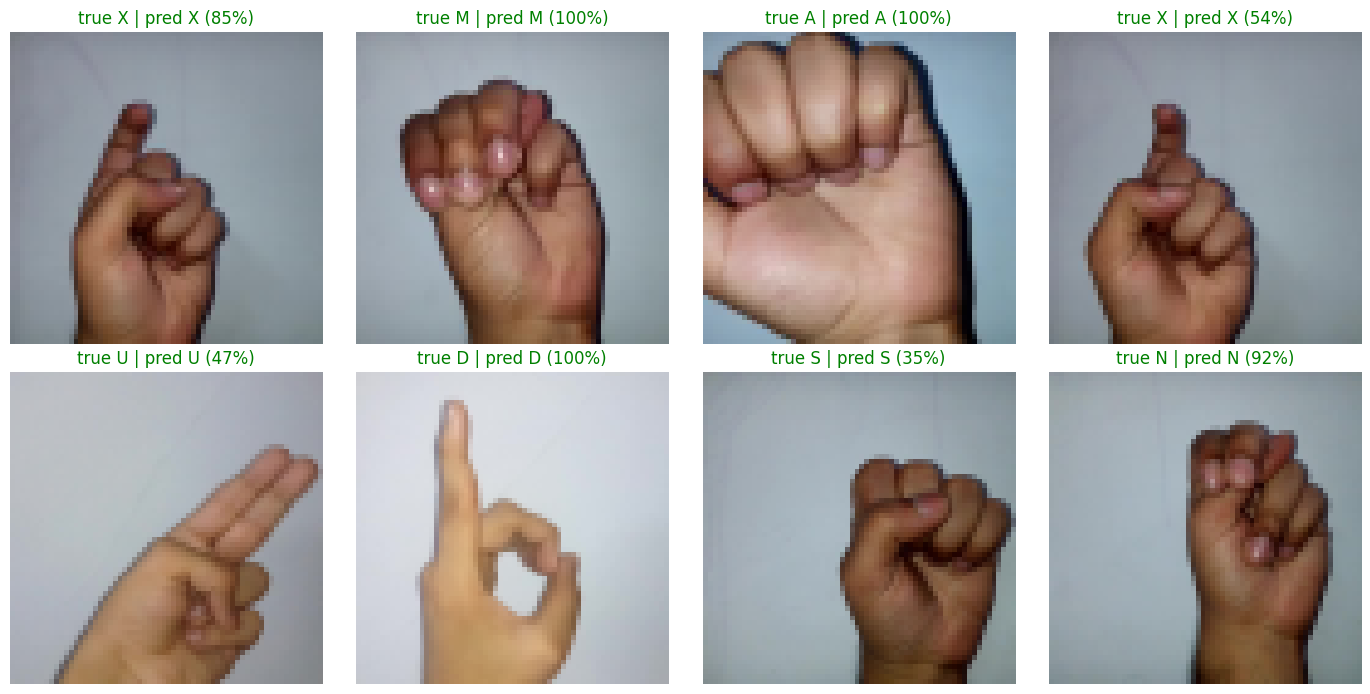

Saved: isl_cnn_model.keras, isl_classes.json


In [21]:
def predict_sign(path, top_k=3):
    img = preprocess(path)
    p = model.predict(img[None], verbose=0)[0]
    top = np.argsort(p)[::-1][:top_k]
    return [(classes[i], float(p[i])) for i in top], img

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.ravel(), np.random.default_rng(1).choice(te, 8, replace=False)):
    r = df.iloc[i]; top, img = predict_sign(r.path)
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"true {r.label} | pred {top[0][0]} ({top[0][1]:.0%})", color="green" if top[0][0] == r.label else "red")
plt.tight_layout(); plt.show()

# Save artefacts for deployment / submission
model.save("isl_cnn_model.keras")
json.dump(classes, open("isl_classes.json", "w"))
print("Saved: isl_cnn_model.keras, isl_classes.json")

## 10. Grouped 5-fold cross-validation
**Why:** Section 7 gives one test number from one split, and that test set is small (about one 20-frame chunk per sign). Cross-validation repeats the experiment on five different splits, so we can report a **mean and a spread** instead of one lucky or unlucky number.

**Design (leakage-safe):**
* Each sign's frames are cut into chunks of about 20 consecutive frames (a short final remainder is merged into the last chunk). Whole chunks are assigned to one of 5 folds, so neighbouring near-duplicate frames never end up in different folds.
* For fold *k*: **test** = fold *k*, **validation** (early stopping and learning-rate control) = fold *k+1*, **train** = the other 3 folds (about 60% of the data). 4 frames at both edges of every test/validation chunk are dropped as a safety buffer.
* A new CNN with the same architecture is trained from scratch in every fold (up to 15 epochs, early stopping). The Random Forest baseline is evaluated on the same folds.
* Results are saved after every fold, so an interrupted run can resume.

Note that training uses only about 60% of the data here (the Section 6 model used about 70%), so fold scores can be slightly lower than the single-split result.

In [6]:
N_FOLDS, CV_CHUNK, CV_BUFFER, CV_EPOCHS = 5, 20, 4, 15

def make_cv_folds(df, n_folds=N_FOLDS, chunk=CV_CHUNK, buffer=CV_BUFFER, seed=SEED):
    """Assign every image to a fold using whole chunks of consecutive frames."""
    rng = np.random.default_rng(seed)
    fold_of = np.full(len(df), -1)               # fold number of each image
    edge = np.zeros(len(df), dtype=bool)         # True = image is within `buffer` frames of a chunk edge
    for c in range(NUM_CLASSES):
        idx = np.where(df.y.values == c)[0]
        idx = idx[np.argsort(df.frame.values[idx])]
        n_chunks = len(idx) // chunk
        assert n_chunks >= n_folds, f"class {classes[c]} has too few chunks for {n_folds} folds"
        order = rng.permutation(n_chunks)        # random chunk order -> round-robin over folds
        for rank, ch in enumerate(order):
            end = len(idx) if ch == n_chunks - 1 else (ch + 1) * chunk
            members = idx[ch * chunk:end]
            fold_of[members] = rank % n_folds
            edge[members[:buffer]] = True; edge[members[-buffer:]] = True
    return fold_of, edge

fold_of, edge = make_cv_folds(df)
rows_ = []
for k in range(N_FOLDS):
    te_k = np.where((fold_of == k) & ~edge)[0]
    va_k = np.where((fold_of == (k + 1) % N_FOLDS) & ~edge)[0]
    tr_k = np.where((fold_of != k) & (fold_of != (k + 1) % N_FOLDS))[0]
    assert not (set(tr_k) & set(te_k)) and not (set(tr_k) & set(va_k)) and not (set(va_k) & set(te_k))
    assert set(y[te_k]) == set(range(NUM_CLASSES)) == set(y[va_k]) == set(y[tr_k]), "a sign is missing from a split"
    rows_.append(dict(fold=k, train=len(tr_k), val=len(va_k), test=len(te_k)))
print("Every sign is present in train, validation and test of every fold; no overlaps.")
display(pd.DataFrame(rows_))

Every sign is present in train, validation and test of every fold; no overlaps.


,fold,train,val,test
0,0,2601,673,810
1,1,2997,550,673
2,2,3236,506,550
3,3,3265,537,506
4,4,2817,810,537


In [7]:
CV_FILE = "cv_results.json"
cv = json.load(open(CV_FILE)) if os.path.exists(CV_FILE) else {}     # resume support
small = lambda arr: np.stack([cv2.resize(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY), (32, 32)) for a in arr]).reshape(len(arr), -1) / 255.0
F_all = small(X)

for k in range(N_FOLDS):
    if str(k) in cv:
        print(f"fold {k}: loaded from {CV_FILE}"); continue
    t0 = time.time()
    te_k = np.where((fold_of == k) & ~edge)[0]
    va_k = np.where((fold_of == (k + 1) % N_FOLDS) & ~edge)[0]
    tr_k = np.where((fold_of != k) & (fold_of != (k + 1) % N_FOLDS))[0]

    keras.backend.clear_session(); tf.random.set_seed(SEED + k)
    m = build_cnn()
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cw_k = dict(enumerate(compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y[tr_k])))
    hist = m.fit(X[tr_k], y[tr_k], validation_data=(X[va_k], y[va_k]), epochs=CV_EPOCHS, batch_size=BATCH_SIZE,
                 class_weight=cw_k, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
                            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)])
    pred_k = m.predict(X[te_k], verbose=0).argmax(1)
    rf_k = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED).fit(F_all[tr_k], y[tr_k])
    rf_pred = rf_k.predict(F_all[te_k])
    cv[str(k)] = dict(cnn_acc=accuracy_score(y[te_k], pred_k), cnn_f1=f1_score(y[te_k], pred_k, average="macro"),
                      rf_acc=accuracy_score(y[te_k], rf_pred), rf_f1=f1_score(y[te_k], rf_pred, average="macro"),
                      epochs=len(hist.history["loss"]), best_val_acc=float(max(hist.history["val_accuracy"])),
                      idx=te_k.tolist(), y_true=y[te_k].tolist(), y_pred=pred_k.tolist())
    json.dump(cv, open(CV_FILE, "w"))
    r = cv[str(k)]
    print(f"fold {k}: CNN acc {r['cnn_acc']:.3f} | CNN F1 {r['cnn_f1']:.3f} | RF acc {r['rf_acc']:.3f} | "
          f"epochs {r['epochs']} | best val acc {r['best_val_acc']:.3f} | {(time.time()-t0)/60:.1f} min")

fold 0: CNN acc 0.922 | CNN F1 0.928 | RF acc 0.742 | epochs 15 | best val acc 0.969 | 5.3 min


fold 1: CNN acc 0.976 | CNN F1 0.970 | RF acc 0.743 | epochs 15 | best val acc 0.956 | 5.3 min


fold 2: CNN acc 0.984 | CNN F1 0.985 | RF acc 0.802 | epochs 15 | best val acc 0.974 | 5.3 min


fold 3: CNN acc 0.968 | CNN F1 0.957 | RF acc 0.749 | epochs 15 | best val acc 0.983 | 6.7 min


fold 4: CNN acc 0.985 | CNN F1 0.986 | RF acc 0.788 | epochs 15 | best val acc 0.977 | 5.3 min


,cnn_acc,cnn_f1,rf_acc,rf_f1,epochs,best_val_acc
fold,,,,,,
0,0.922,0.928,0.742,0.722,15.0,0.969
1,0.976,0.970,0.743,0.750,15.0,0.956
2,0.984,0.985,0.802,0.791,15.0,0.974
3,0.968,0.957,0.749,0.748,15.0,0.983
4,0.985,0.986,0.788,0.805,15.0,0.977


CNN accuracy : 0.967 +/- 0.026  (95% CI 0.935 to 0.999)
CNN macro F1 : 0.965 +/- 0.024  (95% CI 0.935 to 0.995)
RF  accuracy : 0.765 +/- 0.028  (95% CI 0.730 to 0.799)
Paired t-test CNN vs RF over 5 folds: t = 19.38, p = 0.0000


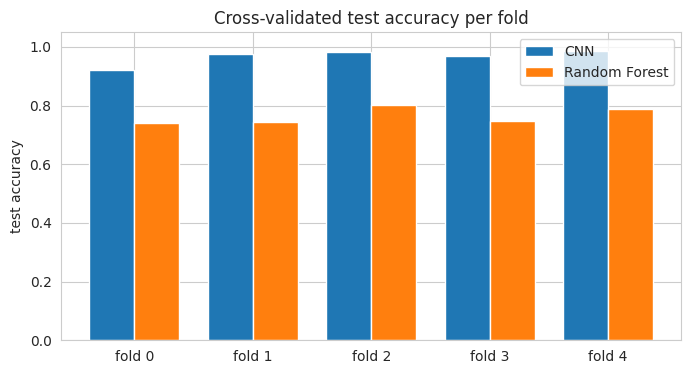

In [8]:
# Summary across folds
res = pd.DataFrame({k: {kk: v[kk] for kk in ["cnn_acc", "cnn_f1", "rf_acc", "rf_f1", "epochs", "best_val_acc"]} for k, v in cv.items()}).T
res.index.name = "fold"
display(res.round(3))

from scipy import stats
def summarize(a):
    a = np.asarray(a, float); n = len(a)
    ci = stats.t.ppf(0.975, n - 1) * a.std(ddof=1) / np.sqrt(n)
    return f"{a.mean():.3f} +/- {a.std(ddof=1):.3f}  (95% CI {a.mean()-ci:.3f} to {a.mean()+ci:.3f})"
print("CNN accuracy :", summarize(res.cnn_acc))
print("CNN macro F1 :", summarize(res.cnn_f1))
print("RF  accuracy :", summarize(res.rf_acc))
t, p = stats.ttest_rel(res.cnn_acc, res.rf_acc)
print(f"Paired t-test CNN vs RF over {len(res)} folds: t = {t:.2f}, p = {p:.4f}")

plt.figure(figsize=(8, 4))
w = 0.38; xs = np.arange(len(res))
plt.bar(xs - w/2, res.cnn_acc, w, label="CNN"); plt.bar(xs + w/2, res.rf_acc, w, label="Random Forest")
plt.xticks(xs, [f"fold {i}" for i in res.index]); plt.ylim(0, 1.05); plt.ylabel("test accuracy"); plt.legend()
plt.title("Cross-validated test accuracy per fold"); plt.show()

Pooled out-of-fold accuracy: 0.964 on 3076 images

Weakest signs across folds:


,mean_acc,std_over_folds,worst_fold
N,0.774,0.192,0.453
V,0.871,0.287,0.357
W,0.873,0.204,0.531
O,0.933,0.149,0.667
X,0.942,0.109,0.750
L,0.960,0.056,0.885
R,0.967,0.075,0.833
S,0.970,0.068,0.848


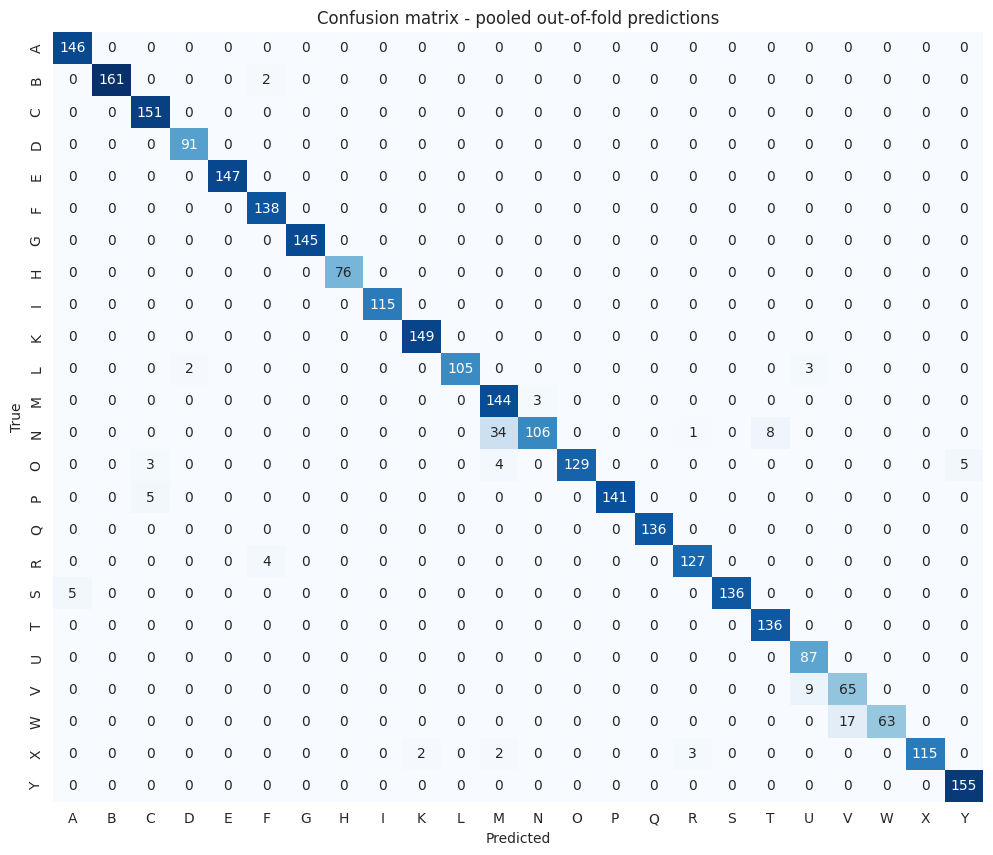

Most frequent confusions (true -> predicted):
  N -> M: 34
  W -> V: 17
  V -> U: 9
  N -> T: 8
  S -> A: 5
  P -> C: 5
  O -> Y: 5
  R -> F: 4

Pooled accuracy by capture setup:


,capture,images,accuracy
0,1088x1920,115,1.000
1,1920x1088,518,0.940
2,640x480,2443,0.967


In [9]:
# Pooled out-of-fold predictions: every usable image is predicted exactly once by a model that never trained on its chunk
yt = np.concatenate([cv[k]["y_true"] for k in cv]); yp = np.concatenate([cv[k]["y_pred"] for k in cv])
ii = np.concatenate([cv[k]["idx"] for k in cv])
print(f"Pooled out-of-fold accuracy: {accuracy_score(yt, yp):.3f} on {len(yt)} images\n")

# Per-class accuracy: mean and spread over folds
pc = pd.DataFrame({k: {classes[c]: np.mean(np.array(v["y_pred"])[np.array(v["y_true"]) == c] == c) for c in range(NUM_CLASSES)} for k, v in cv.items()})
pc_tab = pd.DataFrame({"mean_acc": pc.mean(1), "std_over_folds": pc.std(1), "worst_fold": pc.min(1)}).sort_values("mean_acc")
print("Weakest signs across folds:"); display(pc_tab.head(8).round(3))

cm_cv = confusion_matrix(yt, yp, labels=range(NUM_CLASSES))
plt.figure(figsize=(12, 10)); sns.heatmap(cm_cv, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix - pooled out-of-fold predictions"); plt.show()

off = cm_cv.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], classes[i], classes[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0], reverse=True)[:8]
print("Most frequent confusions (true -> predicted):")
for n, a, b in pairs: print(f"  {a} -> {b}: {n}")

# Accuracy by capture setup (pooled)
cap_cv = df.capture.values[ii]
print("\nPooled accuracy by capture setup:")
display(pd.DataFrame([dict(capture=c, images=int((cap_cv == c).sum()), accuracy=accuracy_score(yt[cap_cv == c], yp[cap_cv == c])) for c in sorted(set(cap_cv))]).round(3))

## 11. Conclusions and limitations

### Results (all numbers come from the executed cells above)
| Model | Evaluation | Accuracy | Macro F1 |
|---|---|---|---|
| Random Forest on 32x32 pixels | naive random split (leaky) | 0.991 | n/a |
| Random Forest on 32x32 pixels | single chunk split | 0.738 | 0.719 |
| Random Forest on 32x32 pixels | 5-fold grouped CV | 0.765 +/- 0.028 | 0.763 |
| CNN | single chunk split | 0.972 | 0.973 |
| **CNN** | **5-fold grouped CV** | **0.967 +/- 0.026** (95% CI 0.935 to 0.999) | **0.965 +/- 0.024** |

* **Headline result:** on unseen chunks of the same recordings, the CNN is correct about **96-97%** of the time. The single-split score (0.972) falls inside the cross-validated range, so it was representative and not a lucky split.
* **The CNN beats the pixel baseline by about 20 percentage points** in every fold (paired t-test over the 5 folds: t = 19.4, p < 0.001), so the gain comes from learned hand-shape features.
* **Leakage matters:** the same Random Forest scores 0.991 on a naive random split but about 0.77 when near-duplicate video frames are kept apart. A random-split number would have been misleading.
* **Performance varies by fold and by sign.** Fold accuracy ranges from 0.922 to 0.985. Pooled over all 3,076 out-of-fold images the accuracy is 0.964. Averaged over folds, the weakest signs are **N (0.77)**, **V (0.87)** and **W (0.87)**; N is sometimes close to 0.45 in a bad fold.
* **Main confusions across all folds:** N -> M (34 images), W -> V (17), V -> U (9) and N -> T (8). These pairs differ mostly in how many fingers are raised or how the thumb is tucked, which is subtle at 64x64 pixels. The single split had suggested S -> A and P -> C as the main problems; cross-validation shows those were minor (5 images each) and that the single test set had hidden the N, V and W weaknesses.
* **Capture setup:** pooled accuracy is 1.00 for the portrait class I, 0.940 for the 1920x1088 classes (D, H, L, U, V, W) and 0.967 for the 640x480 classes. The lower 1920x1088 figure mostly reflects the V/W/U confusions, not an obvious resolution shortcut, although this check cannot rule out lighting or background cues.

### Limitations (please read before relying on these numbers)
1. **Same recordings.** All folds come from the same videos. Chunks are separate, but the signer, background and lighting are shared, so the scores estimate performance on new moments of the same recording, not on new people or new places.
2. **Likely a single signer and a plain background.** We cannot say how the model would perform on other signers, hand sizes, skin tones or cameras. Testing that needs new data.
3. **Folds are not fully independent.** They reuse the same data for training, so the 95% confidence interval (computed from 5 folds) is approximate and probably a little optimistic.
4. **No early stopping happened in cross-validation.** Every fold ran the full 15 epochs, so longer training might help, especially for N, V and W.
5. **Reduced training data per fold.** Each fold trains on about 60% of the images, which can slightly understate what the full-data model achieves.
6. **Static letters only.** J and Z are absent (they involve motion), and words or sentences are out of scope.
7. **Low resolution, no pre-trained model.** Images were reduced to 64x64 and the CNN was trained from scratch on CPU. Higher resolution or a pre-trained backbone could help the finger-count confusions but was not tested.

### Suggested next steps
* Test on a signer who is not in the data; this is the most valuable missing experiment.
* Try 96x96 or larger inputs and longer training, focusing on N, V, W, M, U and T.
* Add a hand-detection step (for example MediaPipe) so the model works on full camera frames.